### Goals

- load models trained with different setups
- with each model, predict the test set  
- compute metrics







In [64]:
import sys
import matplotlib.pyplot as plt
from IPython.display import clear_output
import json
import itertools 
import os 
import random
import matplotlib.pyplot as plt
import pprint
sys.path.append('../')
import tqdm
from pprint import pformat
import pickle

from sklearn.metrics import classification_report
import torch.nn as nn
import rasterio
import numpy as np
import torch
import torch.nn.functional as F
import utils
import pandas as pd
import geopandas as gpd

import model.dataloader as dataloader
from model.dataset import LABEL_MAPPING
from model.model import MultiModalDriverClassifier

import wandb

inverse_label_mapping = {value : key for key, value in LABEL_MAPPING.items()}

In [65]:
import sys
sys.path.append('../')
from evaluate import compute_and_log_metrics

In [66]:

filename = '27_9_modalities'


In [67]:


with open(f'{filename}.pickle', 'rb') as handle:
    loaded_models = pickle.load(handle)


In [68]:
models_ = [model for model in loaded_models if model['config'] != {}]
models__ = [model for model in models_ if 'metrics' in model.keys()]


In [69]:
print(len(models__))

245


In [70]:
models = models__

In [71]:
hyperparams_values = utils.find_keys_with_multiple_values([model['config'] for model in models])

In [72]:
hyperparams_values

{'seed': [420, 422, 423, 424, 425],
 'loc_encoder': {'use': [False, True]},
 'image_encoder': {'use': [False, True]},
 'tabular_encoder': {'use': [False, True]},
 'train_dataset_total_size': [100, 1000, 5000, 200, 10000, 2000, 500]}

In [73]:
labels = pd.read_csv("/home/jan/Documents/EPFL/project_2/data/labels/dataset_v5/labels_no_regrowth.csv")
labels = labels.loc[labels['split'] == 4].reset_index(drop=True) # Get test examples 

targets = labels['driver'].map(LABEL_MAPPING).to_numpy()


In [74]:
def get_models_with_config(_models, target_config):
    
    def has_key_value_pair(d, target):
        if isinstance(d, dict) and isinstance(target, dict):
            for key, value in target.items():
                if key in d:
                    if isinstance(value, dict) and isinstance(d[key], dict):
                        if not has_key_value_pair(d[key], value):
                            return False
                    else:
                        if d[key] != value:
                            return False
                else:
                    return False
            return True
        return d == target
    
    models_with_this_config_combination = []
    for model in _models:
        skip_model = False
        for key in target_config.keys():
            if not has_key_value_pair(model['config'][key],target_config[key]):
            #if model['config'][key] != target_config[key]:
                skip_model = True
                break
        if skip_model:
            continue
        models_with_this_config_combination.append(model)
    
    return models_with_this_config_combination

In [75]:
exclude_keys = ['seed']

combinations = utils.generate_combinations(hyperparams_values, exclude_keys)

In [76]:
#This I need to do in case there is only 1 seed
#hyperparams_values['seed'] = [420]

In [77]:

performance_per_configuration = {}

for combo in combinations:
    
    metrics_per_random_seed = []
    combo_str = ' '.join(pformat(combo, width=1).split())
    #print(combo_str)

    #Compute metrics per each random seed separately
    for seed in hyperparams_values['seed']:
        combo['seed'] = seed 
        
        #Get all models that have the configuration setup 
        model_with_this_config = get_models_with_config(models, combo)
        if not model_with_this_config:
            continue

            
        assert len(model_with_this_config) == 1, f"there should be 1 model with a config, found {len(model_with_this_config)}"
        model_with_this_config = model_with_this_config[0]
        if not 'metrics' in model_with_this_config.keys():
            continue
            
            
        metrics_per_random_seed.append(pd.DataFrame(model_with_this_config['metrics']))


    if not metrics_per_random_seed:
        print("no metrics for: ", combo)
        continue


    # Concatenate DataFrames along a new axis
    concat_df = pd.concat(metrics_per_random_seed, keys=range(len(metrics_per_random_seed)))

    # Compute the mean along the new axis
    mean_df = concat_df.groupby(level=1).mean()

    # Compute the standard deviation along the new axis
    std_df = concat_df.groupby(level=1).std()   
    
    

    performance_per_configuration[combo_str] = {}
    performance_per_configuration[combo_str]['mean'] = mean_df
    performance_per_configuration[combo_str]['std'] = std_df



        

no metrics for:  {'loc_encoder': {'use': False}, 'image_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_dataset_total_size': 100, 'seed': 425}
no metrics for:  {'loc_encoder': {'use': False}, 'image_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_dataset_total_size': 1000, 'seed': 425}
no metrics for:  {'loc_encoder': {'use': False}, 'image_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_dataset_total_size': 5000, 'seed': 425}
no metrics for:  {'loc_encoder': {'use': False}, 'image_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_dataset_total_size': 200, 'seed': 425}
no metrics for:  {'loc_encoder': {'use': False}, 'image_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_dataset_total_size': 10000, 'seed': 425}
no metrics for:  {'loc_encoder': {'use': False}, 'image_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_dataset_total_size': 2000, 'seed': 425}
no metrics for:  

In [78]:
#performance_per_configuration = {key:value for key, value in performance_per_configuration.items() if "{'model_version': 'v2', 'tabular_encoder': {'use': False}" not in key}


In [79]:
#models_100_dst = {key:value for key, value in performance_per_configuration.items() if "'train_dataset_total_size': 100}" in key}
models_200_dst = {key:value for key, value in performance_per_configuration.items() if "'train_dataset_total_size': 200}" in key}
models_500_dst = {key:value for key, value in performance_per_configuration.items() if "'train_dataset_total_size': 500}" in key}
models_1000_dst = {key:value for key, value in performance_per_configuration.items() if "'train_dataset_total_size': 1000}" in key}
models_2000_dst = {key:value for key, value in performance_per_configuration.items() if "'train_dataset_total_size': 2000}" in key}
models_5000_dst = {key:value for key, value in performance_per_configuration.items() if "'train_dataset_total_size': 5000}" in key}
models_10000_dst = {key:value for key, value in performance_per_configuration.items() if "'train_dataset_total_size': 10000}" in key}
#models_20000_dst = {key:value for key, value in performance_per_configuration.items() if "'train_dataset_total_size': 20000}" in key}


In [80]:
def plot_metrics(metrics, metric='accuracy', ylim=(0.2, 1.2) ):
    
    class_names = list(LABEL_MAPPING.keys())
    class_names.append(metric)
    stats = {}
    for model_name, model_stats in metrics.items():
        stats[model_name] = {}
        for cls in class_names:
            stats[model_name][cls] = {}
            stats[model_name][cls]['score'] = metrics[model_name]['mean'][cls]['f1-score']
            stats[model_name][cls]['std'] = metrics[model_name]['std'][cls]['f1-score']

    # Initialize plot
    fig, ax = plt.subplots(figsize=(12, 6))

    # Set the width of the bars
    bar_width = 0.7/len(metrics)

    # Set positions of the bars on the x-axis
    index = np.arange(len(class_names))

    # Plot each model's data

    #for i, model in enumerate(stats.keys()):
    for i, model in enumerate(list(metrics.keys())): #only models with image
        scores = [stats[model][cls]['score'] for cls in class_names]
        stds = [stats[model][cls]['std'] for cls in class_names]
        ax.bar(index + i * bar_width, scores, bar_width, label=model, yerr=stds, capsize=5)

    # Set labels, title, and legend
    #ax.set_xlabel('Class')
    #ax.set_ylabel('Score')
    plt.ylim(bottom=ylim[0])
    plt.ylim(top=ylim[1])
    ax.set_xticks(index + bar_width / 2)
    ax.set_xticklabels(class_names, rotation=45, ha='right')
    ax.legend()

    # Show plot
    plt.tight_layout()
    plt.show()

In [81]:


run_names_mapping = {
    "{'image_encoder': {'use': False}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': False}, xx}" : "location",
    "{'image_encoder': {'use': False}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, xx}" : "tabular",
    "{'image_encoder': {'use': False}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': True}, xx}" : "location + tabular",
    "{'image_encoder': {'use': True}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': False}, xx}" : "image",
    "{'image_encoder': {'use': True}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': False}, xx}" : "image + location",
    "{'image_encoder': {'use': True}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, xx}" : "image + tabular",
    "{'image_encoder': {'use': True}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': True}, xx}" : "image + location + tabular"
}

In [82]:
import ast
import re


# Function to remove 'seed' key-value pairs from a string representation of a dictionary
def remove_seed(entry):
    # Remove the seed key-value pair using regular expressions
    cleaned_entry = re.sub(r"'seed': \d+,? ?", "", entry)
    return cleaned_entry

In [96]:
def process_stats_all(___models, metric='accuracy', n_examples_list=[200, 500, 1000, 2000, 5000, 10000]):

    _models_stats = {}
    
    keys_to_delete = []

    #_models_stats["{'image_encoder': {'use': False}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': False}, xx}"] = {'acc' : [], 'std': []}
    #_models_stats["{'image_encoder': {'use': False}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, xx}"] = {'acc' : [], 'std': []}
    #_models_stats["{'image_encoder': {'use': False}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': True}, xx}"] = {'acc' : [], 'std': []}
    
    _models_stats["{'image_encoder': {'use': True}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': False}, xx}"] = {'acc' : [], 'std': []}
    _models_stats["{'image_encoder': {'use': True}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': False}, xx}"] = {'acc' : [], 'std': []}
    _models_stats["{'image_encoder': {'use': True}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, xx}"] = {'acc' : [], 'std': []}
    _models_stats["{'image_encoder': {'use': True}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': True}, xx}"] = {'acc' : [], 'std': []}
    
    #_models_stats["{'tabular_encoder': {'use': True}, xx}"] = {'acc' : [], 'std': []}
    #_models_stats["{'tabular_encoder': {'use': False}, xx}"] = {'acc' : [], 'std': []}

    for n_examples in n_examples_list:
        #for key in _models.keys():
        selected_models = {key:value for key, value in ___models.items() if f"'train_dataset_total_size': {n_examples}}}" in key}
        for key in _models_stats.keys():
            
            model_name = key.replace("xx", f"'train_dataset_total_size': {n_examples}") 
            try:
                sel_model = selected_models[model_name]
            except KeyError:
                keys_to_delete.append(key)
                continue
            try:
                acc = sel_model['mean'][metric]['f1-score']
                std = sel_model['std'][metric]['f1-score']
            except:
                acc = sel_model['mean']['micro avg']['f1-score']
                std = sel_model['std']['micro avg']['f1-score']
            _models_stats[key]['acc'].append(acc)
            _models_stats[key]['std'].append(std)

    for key in list(set(keys_to_delete)):
        del _models_stats[key]
        
    return _models_stats
    

def plot_metric_v2(_model_stats, metric, run_names=run_names_mapping, n_examples=[200, 500, 1000, 2000, 5000, 10000, 20000]):
    
    processed_stats = process_stats_all(_model_stats, metric, n_examples_list=n_examples)
    
    _plot_dict2(processed_stats, n_examples,run_names)
    
    
def _plot_dict2(_dict, x_axis_vals, names=run_names_mapping):
    #x_indices = range(len(x_axis_vals))  # Create equal spacing for x-axis

    for key, value in _dict.items():
        acc = value['acc']
        std = value['std']

        plt.plot(x_axis_vals, acc, label=names[key])
        plt.fill_between(x_axis_vals, [a - s for a, s in zip(acc, std)], [a + s for a, s in zip(acc, std)], alpha=0.2)

    #plt.xticks(x_indices, x_axis_vals)  # Set x-axis ticks to the original x_axis_vals
    plt.xlabel('Training dataset size')
    plt.ylabel('Accuracy')
    plt.title('Modality comparison')
    plt.legend(bbox_to_anchor=(1.,1))
    plt.xscale('log')
    plt.grid(True)
    plt.show()

In [97]:


performance_per_configuration_renamed = {}

for key, value in performance_per_configuration_per_country['Cambodia'].items():
    performance_per_configuration_renamed[remove_seed(key)] = value
    

In [98]:
processed_stats = process_stats_all(performance_per_configuration_renamed, 'accuracy', n_examples_list=[200, 500, 1000, 2000, 5000, 10000])


In [90]:
performance_per_configuration_renamed["{'image_encoder': {'use': False}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, 'train_dataset_total_size': 100}"]['std']

,pasture,forest plantation,soy,coffee,palm oil,mining,urban,cocoa,rubber,shifting agriculture,other,micro avg,macro avg,weighted avg
f1-score,0.0,0.0,0.0,0.0,0.0,0.0,0.055902,0.0,0.021937,0.0,0.0,0.044958,0.006572,0.021773
precision,0.0,0.0,0.0,0.0,0.0,0.0,0.223607,0.0,0.006597,0.0,0.0,0.044958,0.019773,0.005389
recall,0.0,0.0,0.0,0.0,0.0,0.0,0.031944,0.0,0.048216,0.0,0.0,0.044958,0.006789,0.044958
support,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,0.000000,0.000000,0.000000


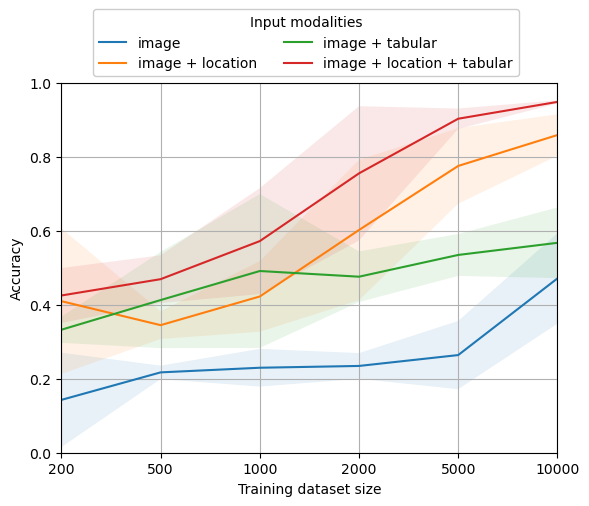

In [99]:
x_axis_vals = [200, 500, 1000, 2000, 5000, 10000]
x_indices = range(len(x_axis_vals)) 

for key, value in processed_stats.items():
    #if not "'image_encoder': {'use': True}" in key:
    #    continue
    
    acc = value['acc']
    std = value['std']

    plt.plot(x_indices, acc, label=run_names_mapping[key])
    plt.fill_between(x_indices, [a - s for a, s in zip(acc, std)], [a + s for a, s in zip(acc, std)], alpha=0.1)

plt.xticks(x_indices, x_axis_vals)  # Map ticks to equally spaced indices
plt.xlabel('Training dataset size')
plt.ylabel('Accuracy')

plt.legend(bbox_to_anchor=(0.05,1), framealpha=1, title="Input modalities", ncol=2, loc="lower left")
plt.grid(True)
plt.ylim(0, 1)
plt.xlim(0, len(x_indices)-1 )  # Adjust to fit x_indices range
plt.show()
#plt.savefig('../paper/.png', dpi=200, bbox_inches='tight')

In [19]:


from model.dataset import LABEL_MAPPING

CLASS_INDICES = [value for key, value in LABEL_MAPPING.items()]
CLASS_NAMES = [key for key in LABEL_MAPPING.keys()]


In [20]:
countries = ['Costa Rica', 'Ghana', 'Cambodia']


In [21]:
model = models[0]
_country = 'Costa Rica'
country_indices = labels.loc[labels.country == _country].index.tolist()
country_targets =  labels.loc[labels.country == _country].driver.map(LABEL_MAPPING).to_numpy()
country_predictions = model['predictions'][country_indices]

_metrics = classification_report(country_targets, country_predictions, output_dict=True,labels=CLASS_INDICES,target_names=CLASS_NAMES,zero_division=0)
pd.DataFrame(_metrics)

,pasture,forest plantation,soy,coffee,palm oil,mining,urban,cocoa,rubber,shifting agriculture,other,micro avg,macro avg,weighted avg
precision,0.0,0.0,0.0,0.428571,0.910798,0.25,0.928571,0.0,0.0,0.0,0.0,0.788732,0.228904,0.842179
recall,0.0,0.0,0.0,0.075000,0.894009,1.00,1.000000,0.0,0.0,0.0,0.0,0.788732,0.269910,0.788732
f1-score,0.0,0.0,0.0,0.127660,0.902326,0.40,0.962963,0.0,0.0,0.0,0.0,0.788732,0.217541,0.797000
support,0.0,0.0,0.0,40.000000,217.000000,1.00,26.000000,0.0,0.0,0.0,0.0,284.000000,284.000000,284.000000


In [ ]:
'''
xx = labels.loc[labels['split'] == 4 ]
xx['preds'] = model_dict['predictions']
xx['preds'] = xx.preds.map(inverse_label_mapping)
labels = pd.read_csv("/home/jan/Documents/EPFL/project_2/data/labels/dataset_v5/labels_grid_5_split.csv")
xx['correct'] = xx.driver == xx.preds

xx['geometry'] = gpd.GeoSeries.from_wkt(xx['geometry'])
xx = gpd.GeoDataFrame(xx)
xx.crs = 4326

xx.to_file('../data/tmp/preds.gpkg')
'''

# Compute metrics per country

### Classification report outputs
The reported averages include macro average (averaging the unweighted mean per label), weighted average (averaging the support-weighted mean per label), and sample average (only for multilabel classification). \

**Micro average (averaging the total true positives, false negatives and false positives) is only shown for multi-label or multi-class with a subset of classes, because it corresponds to accuracy otherwise and would be the same for all metrics.**

In [25]:


from model.dataset import LABEL_MAPPING

CLASS_INDICES = [value for key, value in LABEL_MAPPING.items()]
CLASS_NAMES = [key for key in LABEL_MAPPING.keys()]


In [26]:
countries = ['Costa Rica', 'Ghana', 'Cambodia', 'rest']


performance_per_configuration_per_country = {}



for _country in countries:
    if _country == 'rest':
        country_indices = labels.loc[~labels.country.isin(['Costa Rica', 'Ghana', 'Cambodia'])].index.tolist()
        country_targets =  labels.loc[~labels.country.isin(['Costa Rica', 'Ghana', 'Cambodia'])].driver.map(LABEL_MAPPING).to_numpy()
            
    else:
        country_indices = labels.loc[labels.country == _country].index.tolist()
        country_targets =  labels.loc[labels.country == _country].driver.map(LABEL_MAPPING).to_numpy()
    
    performance_per_configuration_per_country[_country] = {}


    for combo in combinations:

        metrics_per_random_seed = []
        combo_str = ' '.join(pformat(combo, width=1).split())
        combo_str = remove_seed(combo_str)

        #Compute metrics per each random seed separately
        for seed in hyperparams_values['seed']:
            combo['seed'] = seed 

            #Get all models that have the configuration setup 
            model_with_this_config = get_models_with_config(models, combo)
            if not model_with_this_config:
                continue

            assert len(model_with_this_config) == 1, f"there should be 1 model with a config, found {len(model_with_this_config)}"
            model_with_this_config = model_with_this_config[0]
            if not 'predictions' in model_with_this_config.keys():
                continue

            country_predictions = model_with_this_config['predictions'][country_indices]
            country_metrics = classification_report(country_targets, country_predictions, output_dict=True,labels=CLASS_INDICES,target_names=CLASS_NAMES,zero_division=0)


            metrics_per_random_seed.append(pd.DataFrame(country_metrics))

        if not metrics_per_random_seed:
            print("no metrics for: ", combo)
            continue


        # Concatenate DataFrames along a new axis
        concat_df = pd.concat(metrics_per_random_seed, keys=range(len(metrics_per_random_seed)))

        # Compute the mean along the new axis
        mean_df = concat_df.groupby(level=1).mean()

        # Compute the standard deviation along the new axis
        std_df = concat_df.groupby(level=1).std()   



        performance_per_configuration_per_country[_country][combo_str] = {}
        performance_per_configuration_per_country[_country][combo_str]['mean'] = mean_df
        performance_per_configuration_per_country[_country][combo_str]['std'] = std_df



        
        

no metrics for:  {'loc_encoder': {'use': False}, 'image_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_dataset_total_size': 100, 'seed': 425}
no metrics for:  {'loc_encoder': {'use': False}, 'image_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_dataset_total_size': 1000, 'seed': 425}
no metrics for:  {'loc_encoder': {'use': False}, 'image_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_dataset_total_size': 5000, 'seed': 425}
no metrics for:  {'loc_encoder': {'use': False}, 'image_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_dataset_total_size': 200, 'seed': 425}
no metrics for:  {'loc_encoder': {'use': False}, 'image_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_dataset_total_size': 10000, 'seed': 425}
no metrics for:  {'loc_encoder': {'use': False}, 'image_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_dataset_total_size': 2000, 'seed': 425}
no metrics for:  

In [42]:
key = "{'image_encoder': {'use': True}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': True}, 'train_dataset_total_size': 10000}"

performance_per_configuration_per_country['Ghana'][key]['mean']


,pasture,forest plantation,soy,coffee,palm oil,mining,urban,cocoa,rubber,shifting agriculture,other,micro avg,macro avg,weighted avg
f1-score,0.0,0.0,0.0,0.0,0.660336,0.663898,0.861671,0.965092,0.0,0.0,0.0,0.927075,0.286454,0.923632
precision,0.0,0.0,0.0,0.0,0.830869,0.949688,0.795126,0.944114,0.0,0.0,0.0,0.927075,0.319982,0.939021
recall,0.0,0.0,0.0,0.0,0.581818,0.519697,0.951724,0.987129,0.0,0.0,0.0,0.927075,0.276397,0.927075
support,0.0,0.0,0.0,0.0,22.000000,132.000000,29.000000,1010.000000,0.0,0.0,0.0,1193.000000,1193.000000,1193.000000


In [43]:
key = "{'image_encoder': {'use': True}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_dataset_total_size': 10000}"

performance_per_configuration_per_country['Ghana'][key]['mean']


,pasture,forest plantation,soy,coffee,palm oil,mining,urban,cocoa,rubber,shifting agriculture,other,micro avg,macro avg,weighted avg
f1-score,0.0,0.0,0.0,0.0,0.408985,0.806725,0.902654,0.917458,0.0,0.0,0.0,0.850293,0.275984,0.895469
precision,0.0,0.0,0.0,0.0,0.299685,0.884436,0.873586,0.981615,0.0,0.0,0.0,0.850293,0.276302,0.955661
recall,0.0,0.0,0.0,0.0,0.681818,0.743939,0.937931,0.865347,0.0,0.0,0.0,0.850293,0.293549,0.850293
support,0.0,0.0,0.0,0.0,22.000000,132.000000,29.000000,1010.000000,0.0,0.0,0.0,1193.000000,1193.000000,1193.000000


In [44]:
key = "{'image_encoder': {'use': True}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': False}, 'train_dataset_total_size': 10000}"

performance_per_configuration_per_country['Ghana'][key]['mean']


,pasture,forest plantation,soy,coffee,palm oil,mining,urban,cocoa,rubber,shifting agriculture,other,micro avg,macro avg,weighted avg
f1-score,0.0,0.0,0.0,0.0,0.617095,0.735023,0.821699,0.965343,0.0,0.0,0.0,0.922716,0.285378,0.929945
precision,0.0,0.0,0.0,0.0,0.629794,0.958683,0.732443,0.963394,0.0,0.0,0.0,0.922716,0.298574,0.951107
recall,0.0,0.0,0.0,0.0,0.718182,0.603030,0.958621,0.967921,0.0,0.0,0.0,0.922716,0.295250,0.922716
support,0.0,0.0,0.0,0.0,22.000000,132.000000,29.000000,1010.000000,0.0,0.0,0.0,1193.000000,1193.000000,1193.000000


In [ ]:
#countries = ['Costa Rica', 'Ghana', 'Cambodia', 'rest']


In [45]:
key = "{'image_encoder': {'use': True}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_dataset_total_size': 10000}"

performance_per_configuration_per_country['Cambodia'][key]['mean']


,pasture,forest plantation,soy,coffee,palm oil,mining,urban,cocoa,rubber,shifting agriculture,other,accuracy,macro avg,weighted avg
f1-score,0.0,0.0,0.0,0.0,0.175619,0.236364,0.920444,0.0,0.602291,0.0,0.0,0.471572,0.175883,0.599246
precision,0.0,0.0,0.0,0.0,0.100802,0.191667,1.000000,0.0,0.997221,0.0,0.0,0.471572,0.208154,0.959288
recall,0.0,0.0,0.0,0.0,0.800000,0.333333,0.857143,0.0,0.441176,0.0,0.0,0.471572,0.221059,0.471572
support,0.0,0.0,0.0,0.0,10.000000,3.000000,14.000000,0.0,272.000000,0.0,0.0,0.471572,299.000000,299.000000


In [46]:
key = "{'image_encoder': {'use': True}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': False}, 'train_dataset_total_size': 10000}"

performance_per_configuration_per_country['Cambodia'][key]['mean']


,pasture,forest plantation,soy,coffee,palm oil,mining,urban,cocoa,rubber,shifting agriculture,other,micro avg,macro avg,weighted avg
f1-score,0.0,0.0,0.0,0.0,0.157576,0.307143,0.946439,0.0,0.924584,0.0,0.0,0.859532,0.212340,0.893760
precision,0.0,0.0,0.0,0.0,0.293750,0.290000,1.000000,0.0,0.969375,0.0,0.0,0.859532,0.232102,0.941397
recall,0.0,0.0,0.0,0.0,0.220000,0.333333,0.900000,0.0,0.886765,0.0,0.0,0.859532,0.212736,0.859532
support,0.0,0.0,0.0,0.0,10.000000,3.000000,14.000000,0.0,272.000000,0.0,0.0,299.000000,299.000000,299.000000


In [47]:
key = "{'image_encoder': {'use': True}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': True}, 'train_dataset_total_size': 10000}"

performance_per_configuration_per_country['Cambodia'][key]['mean']


,pasture,forest plantation,soy,coffee,palm oil,mining,urban,cocoa,rubber,shifting agriculture,other,micro avg,macro avg,weighted avg
f1-score,0.0,0.0,0.0,0.0,0.415027,0.287143,0.954416,0.0,0.973991,0.0,0.0,0.949164,0.239143,0.947489
precision,0.0,0.0,0.0,0.0,0.446190,0.270000,1.000000,0.0,0.970977,0.0,0.0,0.949164,0.244288,0.947751
recall,0.0,0.0,0.0,0.0,0.420000,0.333333,0.914286,0.0,0.977206,0.0,0.0,0.949164,0.240439,0.949164
support,0.0,0.0,0.0,0.0,10.000000,3.000000,14.000000,0.0,272.000000,0.0,0.0,299.000000,299.000000,299.000000


In [51]:
key = "{'image_encoder': {'use': True}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_dataset_total_size': 10000}"

performance_per_configuration_per_country['Costa Rica'][key]['mean']


,pasture,forest plantation,soy,coffee,palm oil,mining,urban,cocoa,rubber,shifting agriculture,other,micro avg,macro avg,weighted avg,accuracy
f1-score,0.0,0.0,0.0,0.360400,0.834454,0.0,0.912215,0.0,0.0,0.0,0.0,0.669014,0.191552,0.771867,0.700704
precision,0.0,0.0,0.0,0.786667,0.980575,0.0,0.938416,0.0,0.0,0.0,0.0,0.669014,0.245969,0.945952,0.700704
recall,0.0,0.0,0.0,0.235000,0.733641,0.0,0.892308,0.0,0.0,0.0,0.0,0.669014,0.169177,0.675352,0.700704
support,0.0,0.0,0.0,40.000000,217.000000,1.0,26.000000,0.0,0.0,0.0,0.0,284.000000,284.000000,284.000000,0.700704


In [54]:
key = "{'image_encoder': {'use': True}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': False}, 'train_dataset_total_size': 10000}"

performance_per_configuration_per_country['Costa Rica'][key]['mean']


,pasture,forest plantation,soy,coffee,palm oil,mining,urban,cocoa,rubber,shifting agriculture,other,micro avg,macro avg,weighted avg
f1-score,0.0,0.0,0.0,0.413965,0.898419,0.433333,0.946403,0.0,0.0,0.0,0.0,0.816901,0.244738,0.832941
precision,0.0,0.0,0.0,0.495241,0.942715,0.346667,0.940518,0.0,0.0,0.0,0.0,0.816901,0.247740,0.877390
recall,0.0,0.0,0.0,0.480000,0.862673,0.800000,0.953846,0.0,0.0,0.0,0.0,0.816901,0.281502,0.816901
support,0.0,0.0,0.0,40.000000,217.000000,1.000000,26.000000,0.0,0.0,0.0,0.0,284.000000,284.000000,284.000000


In [55]:
key = "{'image_encoder': {'use': True}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': True}, 'train_dataset_total_size': 10000}"

performance_per_configuration_per_country['Costa Rica'][key]['mean']


,pasture,forest plantation,soy,coffee,palm oil,mining,urban,cocoa,rubber,shifting agriculture,other,micro avg,macro avg,weighted avg
f1-score,0.0,0.0,0.0,0.110573,0.900371,0.237143,0.954928,0.0,0.0,0.0,0.0,0.795775,0.200274,0.791791
precision,0.0,0.0,0.0,0.542857,0.893040,0.150000,0.943355,0.0,0.0,0.0,0.0,0.795775,0.229932,0.845709
recall,0.0,0.0,0.0,0.065000,0.910599,0.600000,0.969231,0.0,0.0,0.0,0.0,0.795775,0.231348,0.795775
support,0.0,0.0,0.0,40.000000,217.000000,1.000000,26.000000,0.0,0.0,0.0,0.0,284.000000,284.000000,284.000000


In [29]:
performance_per_configuration_per_country['Cambodia'].keys()

dict_keys(["{'image_encoder': {'use': False}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, 'train_dataset_total_size': 100}", "{'image_encoder': {'use': False}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, 'train_dataset_total_size': 1000}", "{'image_encoder': {'use': False}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, 'train_dataset_total_size': 5000}", "{'image_encoder': {'use': False}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, 'train_dataset_total_size': 200}", "{'image_encoder': {'use': False}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, 'train_dataset_total_size': 10000}", "{'image_encoder': {'use': False}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, 'train_dataset_total_size': 2000}", "{'image_encoder': {'use': False}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, 'train_dataset_total_size': 500}", "{'image_encoder': {'use': True}, 'loc_

In [61]:
key = "{'image_encoder': {'use': True}, 'loc_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_dataset_total_size': 1000}"

performance_per_configuration_per_country['rest'][key]['mean']


,pasture,forest plantation,soy,coffee,palm oil,mining,urban,cocoa,rubber,shifting agriculture,other,accuracy,macro avg,weighted avg
f1-score,0.682712,0.535608,0.716148,0.246926,0.496585,0.719915,0.835962,0.656826,0.374997,0.667789,0.532698,0.610943,0.587833,0.615705
precision,0.724923,0.507342,0.764890,0.216032,0.531118,0.777676,0.806573,0.522929,0.377179,0.654788,0.598799,0.610943,0.589295,0.636815
recall,0.655450,0.575120,0.680726,0.308861,0.468263,0.671212,0.871579,0.914563,0.383607,0.683274,0.485315,0.610943,0.608906,0.610943
support,422.000000,209.000000,441.000000,158.000000,167.000000,396.000000,190.000000,103.000000,183.000000,281.000000,429.000000,0.610943,2979.000000,2979.000000


In [62]:
key = "{'image_encoder': {'use': True}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': False}, 'train_dataset_total_size': 1000}"

performance_per_configuration_per_country['rest'][key]['mean']


,pasture,forest plantation,soy,coffee,palm oil,mining,urban,cocoa,rubber,shifting agriculture,other,accuracy,macro avg,weighted avg
f1-score,0.758768,0.572269,0.759043,0.540291,0.578347,0.749831,0.841567,0.875978,0.508001,0.968139,0.690150,0.726754,0.712944,0.726631
precision,0.772177,0.545451,0.738663,0.486836,0.641702,0.825500,0.845465,0.797390,0.550555,0.978812,0.694678,0.726754,0.716112,0.736212
recall,0.756398,0.603828,0.786848,0.613924,0.540120,0.689899,0.847368,0.972816,0.476503,0.958719,0.686247,0.726754,0.721152,0.726754
support,422.000000,209.000000,441.000000,158.000000,167.000000,396.000000,190.000000,103.000000,183.000000,281.000000,429.000000,0.726754,2979.000000,2979.000000


In [63]:
key = "{'image_encoder': {'use': True}, 'loc_encoder': {'use': True}, 'tabular_encoder': {'use': True}, 'train_dataset_total_size': 1000}"

performance_per_configuration_per_country['rest'][key]['mean']


,pasture,forest plantation,soy,coffee,palm oil,mining,urban,cocoa,rubber,shifting agriculture,other,accuracy,macro avg,weighted avg
f1-score,0.744945,0.564226,0.742699,0.568239,0.598787,0.752863,0.851231,0.941644,0.484512,0.989344,0.699024,0.730245,0.721592,0.729442
precision,0.780087,0.515561,0.745518,0.518293,0.668936,0.821167,0.859536,0.891760,0.540982,0.985906,0.675693,0.730245,0.727585,0.740376
recall,0.726540,0.630622,0.748753,0.637975,0.561677,0.696465,0.848421,0.998058,0.446995,0.992883,0.726340,0.730245,0.728612,0.730245
support,422.000000,209.000000,441.000000,158.000000,167.000000,396.000000,190.000000,103.000000,183.000000,281.000000,429.000000,0.730245,2979.000000,2979.000000


In [ ]:
dst_size = 1000

ValueError: Invalid format specifier ' True' for object of type 'str'

,pasture,forest plantation,soy,coffee,palm oil,mining,urban,cocoa,rubber,shifting agriculture,other,micro avg,macro avg,weighted avg
f1-score,0.0,0.0,0.0,0.110573,0.900371,0.237143,0.954928,0.0,0.0,0.0,0.0,0.795775,0.200274,0.791791
precision,0.0,0.0,0.0,0.542857,0.893040,0.150000,0.943355,0.0,0.0,0.0,0.0,0.795775,0.229932,0.845709
recall,0.0,0.0,0.0,0.065000,0.910599,0.600000,0.969231,0.0,0.0,0.0,0.0,0.795775,0.231348,0.795775
support,0.0,0.0,0.0,40.000000,217.000000,1.000000,26.000000,0.0,0.0,0.0,0.0,284.000000,284.000000,284.000000


In [268]:
for key, value in performance_per_configuration_per_country['Ghana'].items():
    print(val)

["{'loc_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_examples_per_class': 100}"]['mean']



In [267]:
for key, value in performance_per_configuration_per_country['Cambodia'].items():
    print(key)
    print(value['mean'].keys())

{'loc_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_examples_per_class': 100}
Index(['pasture', 'forest plantation', 'soy', 'coffee', 'palm oil', 'mining',
       'urban', 'cocoa', 'rubber', 'forest regrowth', 'shifting agriculture',
       'other', 'accuracy', 'macro avg', 'weighted avg', 'micro avg'],
      dtype='object')
{'loc_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_examples_per_class': 1000}
Index(['pasture', 'forest plantation', 'soy', 'coffee', 'palm oil', 'mining',
       'urban', 'cocoa', 'rubber', 'forest regrowth', 'shifting agriculture',
       'other', 'accuracy', 'macro avg', 'weighted avg', 'micro avg'],
      dtype='object')
{'loc_encoder': {'use': False}, 'tabular_encoder': {'use': False}, 'train_examples_per_class': 200}
Index(['pasture', 'forest plantation', 'soy', 'coffee', 'palm oil', 'mining',
       'urban', 'cocoa', 'rubber', 'forest regrowth', 'shifting agriculture',
       'other', 'accuracy', 'macro avg', 'wei

In [287]:
def process_stats_country(___models, metric='accuracy'):

    _models_stats = {}
    
    _models_stats["{'loc_encoder': {'use': False}, 'tabular_encoder': {'use': False}, xx}"] = {'acc' : [], 'std': []}
    _models_stats["{'loc_encoder': {'use': True}, 'tabular_encoder': {'use': False}, xx}"] = {'acc' : [], 'std': []}
    _models_stats["{'loc_encoder': {'use': False}, 'tabular_encoder': {'use': True}, xx}"] = {'acc' : [], 'std': []}
    _models_stats["{'loc_encoder': {'use': True}, 'tabular_encoder': {'use': True}, xx}"] = {'acc' : [], 'std': []}

    for n_examples in [20, 50, 100, 200, 500, 1000, 3000]:

        #for key in _models.keys():
        selected_models = {key:value for key, value in ___models.items() if f"'train_examples_per_class': {n_examples}}}" in key}
        for key in _models_stats.keys():
            model_name = key.replace("xx", f"'train_examples_per_class': {n_examples}") 
            sel_model = selected_models[model_name]
            try:
                acc = sel_model['mean'][metric]['f1-score']
                std = sel_model['std'][metric]['f1-score']
            except KeyError:
                acc = sel_model['mean']['accuracy']['f1-score']
                std = sel_model['std']['accuracy']['f1-score']                
            _models_stats[key]['acc'].append(acc)
            _models_stats[key]['std'].append(std)


        
    return _models_stats
    

In [288]:
#costa_rica = process_stats_all(performance_per_configuration_per_country['Costa Rica'], metric='micro avg')
ghana = process_stats_country(performance_per_configuration_per_country['Ghana'], metric='micro avg')
#cambodia = process_stats_country(performance_per_configuration_per_country['Cambodia'], metric='micro avg')

In [289]:
rest = process_stats_country(performance_per_configuration_per_country['rest'], metric='micro avg')

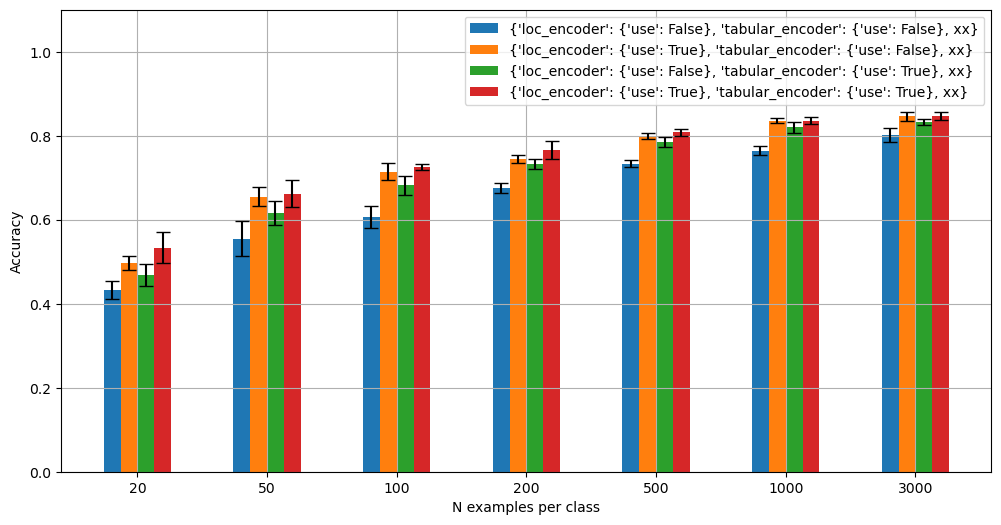

In [290]:
_plot_dict5(rest, [20, 50, 100, 200, 500, 1000, 3000])

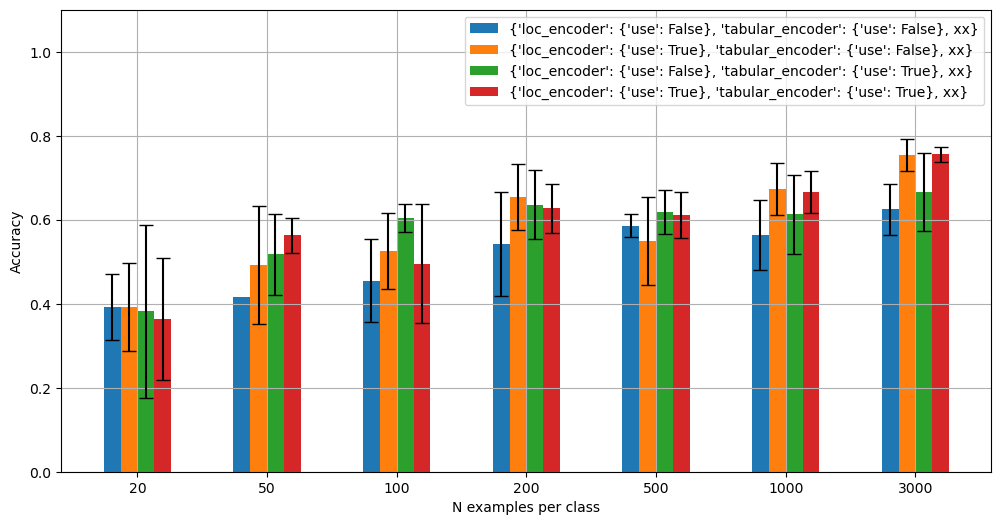

In [281]:
_plot_dict5(costa_rica, [20, 50, 100, 200, 500, 1000, 3000])

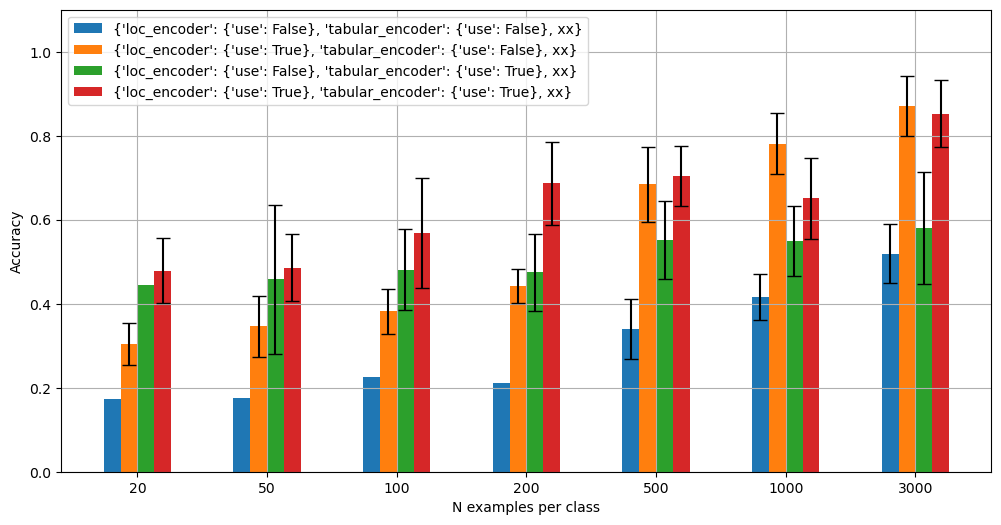

In [278]:
_plot_dict5(cambodia, [20, 50, 100, 200, 500, 1000, 3000])

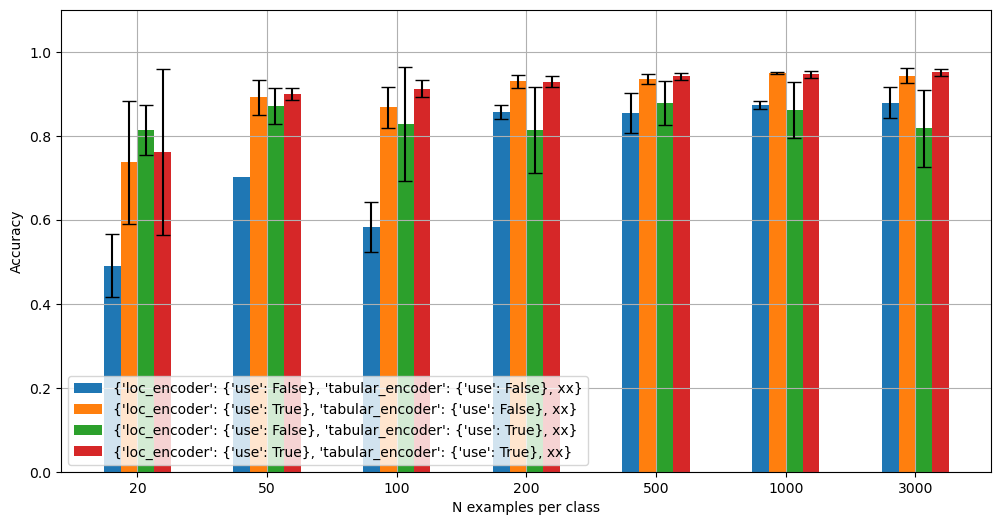

In [280]:
_plot_dict5(ghana, [20, 50, 100, 200, 500, 1000, 3000])

In [72]:
_country = "Cambodia"
models_100_per_class_country = {key:value for key, value in performance_per_configuration_per_country[_country].items() if "'train_examples_per_class': 100}" in key}
models_500_per_class_country = {key:value for key, value in performance_per_configuration_per_country[_country].items() if "'train_examples_per_class': 500}" in key}


In [ ]:
_plot_dict4(_models_stats_all, [20, 50, 100, 200, 500, 1000])

In [73]:
list(models_100_per_class_country.keys())

["{'seed': 425, 'tabular_encoder': {'use': False}, 'train_examples_per_class': 100}",
 "{'seed': 425, 'tabular_encoder': {'use': True}, 'train_examples_per_class': 100}"]

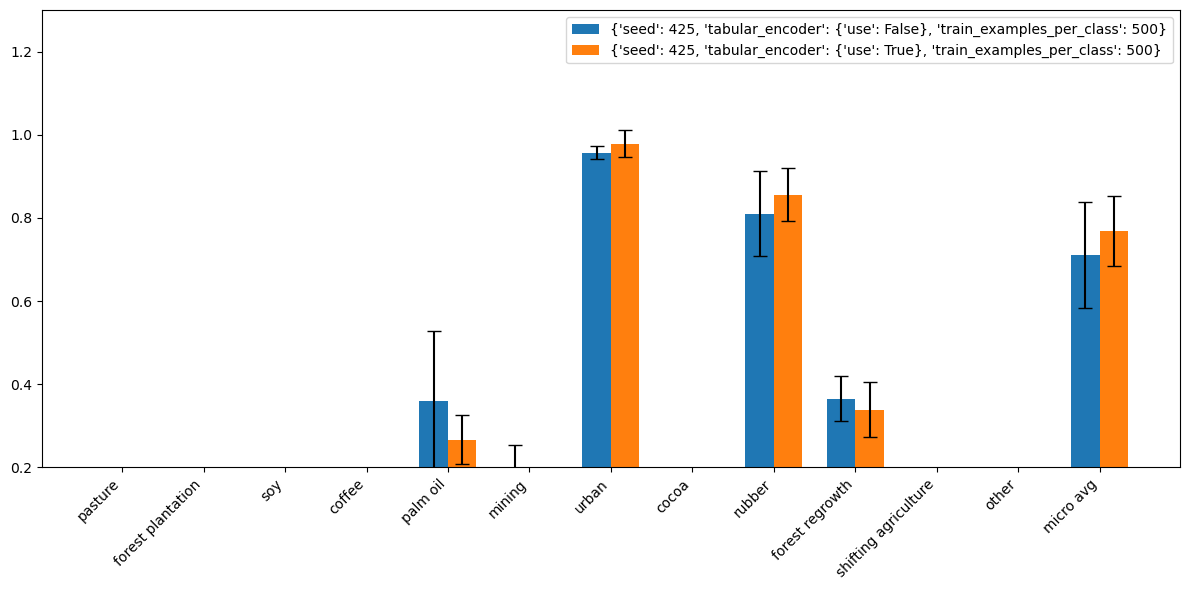

In [77]:
plot_metrics(models_500_per_class_country, metric='micro avg', ylim=(0.2,1.3))


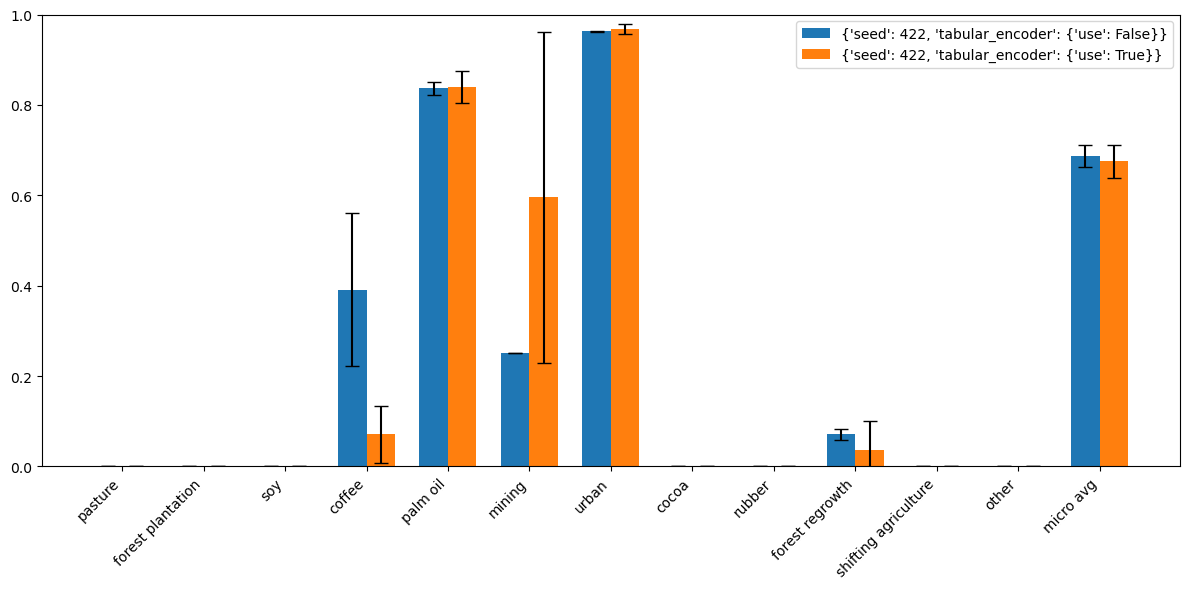

In [31]:
plot_metrics(performance_per_configuration_per_country['Costa Rica'], metric='micro avg', ylim=(0,1))


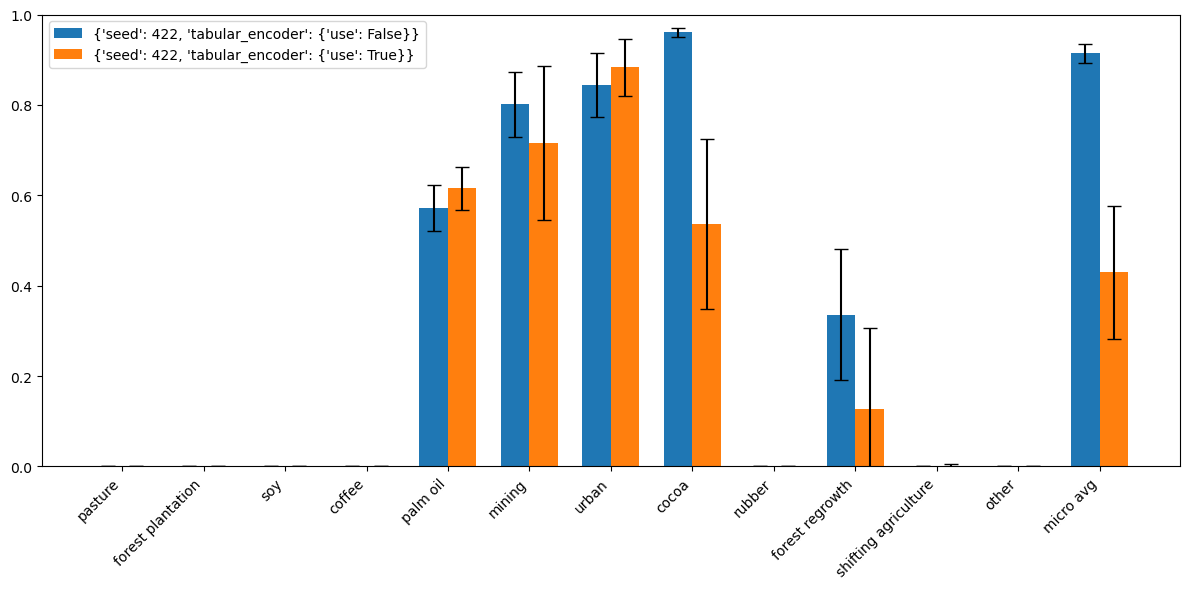

In [30]:
plot_metrics(performance_per_configuration_per_country['Ghana'], metric='micro avg', ylim=(0,1))


In [46]:
labels['model2_pred'] = models[2]['predictions']
labels['model2_pred'] = labels['model2_pred'].map(inverse_label_mapping)

In [55]:
labels['model_1_correct'] = labels.driver == labels.model1_pred
labels['model_2_correct'] = labels.driver == labels.model2_pred

In [56]:
#labels['geometry'] = gpd.GeoSeries.from_wkt(labels['geometry'])
gpd.GeoDataFrame(labels).to_file('../data/tmp/preds.gpkg')

In [57]:
labels

,driver,sampleid,dataset,country,geometry,block_id,split,model1_pred,model2_pred,model_1_correct,model_2_correct
0,coffee,190000083,manual_annotation.csv,Costa Rica,POINT (-84.25407 10.14892),92.0,4,coffee,mining,True,False
1,coffee,190000084,manual_annotation.csv,Costa Rica,POINT (-84.37103 10.14003),92.0,4,palm oil,cocoa,False,False
2,coffee,190000085,manual_annotation.csv,Costa Rica,POINT (-84.38558 10.13114),92.0,4,palm oil,cocoa,False,False
3,coffee,190000086,manual_annotation.csv,Costa Rica,POINT (-84.32467 10.11335),92.0,4,cocoa,cocoa,False,False
4,coffee,190000087,manual_annotation.csv,Costa Rica,POINT (-84.40768 10.05999),92.0,4,palm oil,cocoa,False,False
...,...,...,...,...,...,...,...,...,...,...,...
5072,forest plantation,10655614,mapbiomas.csv,Brazil,POINT (-42.75639 -19.48473),33.0,4,forest plantation,coffee,True,False
5073,forest plantation,10655563,mapbiomas.csv,Brazil,POINT (-42.41844 -19.46694),33.0,4,forest plantation,forest plantation,True,True
5074,forest plantation,10656797,mapbiomas.csv,Brazil,POINT (-43.34335 -19.97386),33.0,4,forest plantation,forest plantation,True,True
5075,forest plantation,10653072,mapbiomas.csv,Brazil,POINT (-42.43623 -18.53314),33.0,4,forest plantation,forest plantation,True,True


In [40]:
models[2]['predictions']

{'seed': 421,
 'epochs': 75,
 'batch_size': 64,
 'classifier': {'type': 'transformer',
  'attention_heads': 8,
  'transformer_layers': 3},
 'in_channels': 4,
 'loc_encoder': {'use': True, 'positional_embedding': 'cartesian3d'},
 'n_parameters': 13160333,
 'val_dst_size': 5077,
 'weight_decay': 0.002,
 'embedding_dim': 128,
 'image_encoder': {'use': True,
  'type': 'cnn',
  'backbone': 'resnet18',
  'moco_weights': False,
  'freezing_patience': 4,
  'pretrained_backbone': True},
 'learning_rate': 0.0005,
 'model_version': 'v1',
 'folds_to_split': {'column': 'split',
  'mapping': {'0': 'train',
   '1': 'train',
   '2': 'train',
   '3': 'train',
   '4': 'val'}},
 'train_dst_size': 6000,
 'use_forestloss': True,
 'tabular_encoder': {'use': True,
  'type': 'token',
  'dataset': 'deduce',
  'temporal_processing': 'dynamic'},
 'randomize_labels': False,
 'forestloss_params': {'sigma': 6, 'kernel_size': 15, 'apply_after_layer': 3},
 'early_stopping_patience': 75,
 'train_examples_per_class': 5

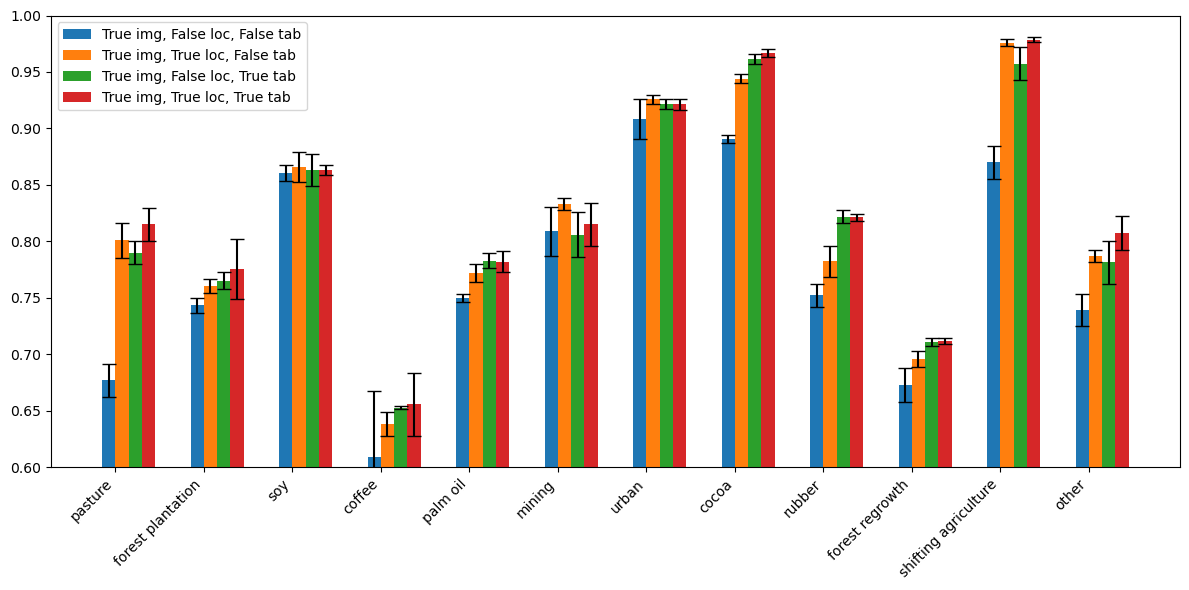

In [195]:
import matplotlib.pyplot as plt


# Extract classes and models
classes = list(stats['False img, False loc, True tab'].keys())
models = list(stats.keys())

# Initialize plot
fig, ax = plt.subplots(figsize=(12, 6))

# Set the width of the bars
bar_width = 0.15

# Set positions of the bars on the x-axis
index = np.arange(len(classes))

# Plot each model's data

#for i, model in enumerate(stats.keys()):
for i, model in enumerate(list(performance_per_configuration.keys())): #only models with image
    scores = [stats[model][cls]['score'] for cls in classes]
    stds = [stats[model][cls]['std'] for cls in classes]
    ax.bar(index + i * bar_width, scores, bar_width, label=model, yerr=stds, capsize=5)

# Set labels, title, and legend
#ax.set_xlabel('Class')
#ax.set_ylabel('Score')
plt.ylim(bottom=0.6)
plt.ylim(top=1)
ax.set_xticks(index + bar_width / 2)
ax.set_xticklabels(classes, rotation=45, ha='right')
ax.legend()

# Show plot
plt.tight_layout()
plt.show()

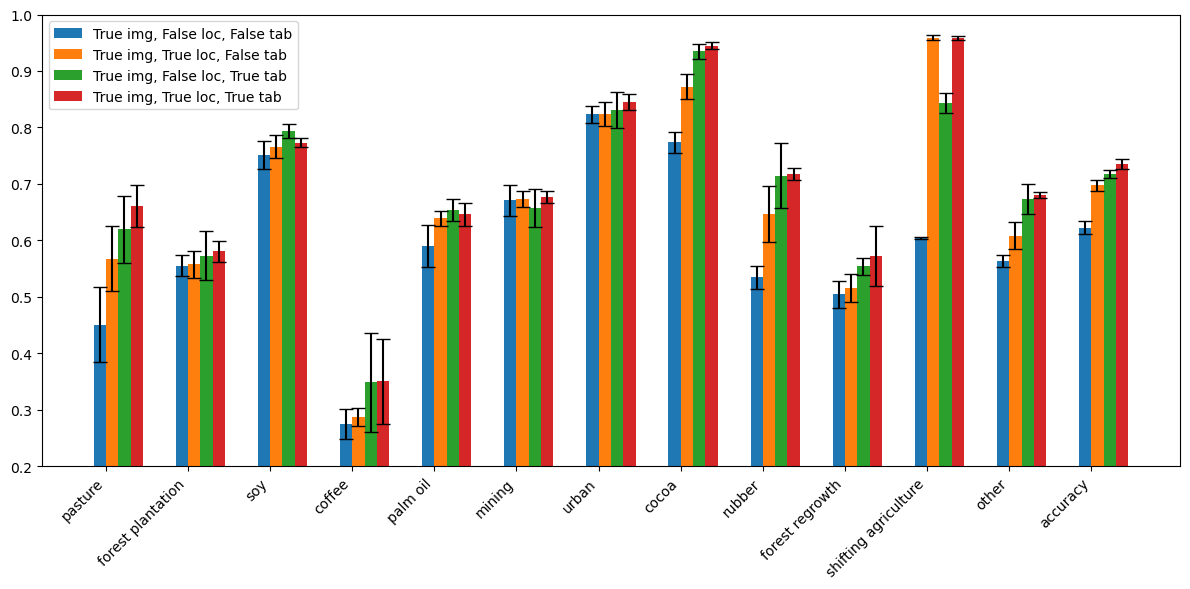

In [44]:
import matplotlib.pyplot as plt


# Extract classes and models
classes = list(stats['False img, False loc, True tab'].keys())
models = list(stats.keys())

# Initialize plot
fig, ax = plt.subplots(figsize=(12, 6))

# Set the width of the bars
bar_width = 0.15

# Set positions of the bars on the x-axis
index = np.arange(len(classes))

# Plot each model's data

#for i, model in enumerate(stats.keys()):
for i, model in enumerate(img_only_reordered): #only models with image
    scores = [stats[model][cls]['score'] for cls in classes]
    stds = [stats[model][cls]['std'] for cls in classes]
    ax.bar(index + i * bar_width, scores, bar_width, label=model, yerr=stds, capsize=5)

# Set labels, title, and legend
#ax.set_xlabel('Class')
#ax.set_ylabel('Score')
plt.ylim(bottom=0.2)
plt.ylim(top=1)
ax.set_xticks(index + bar_width / 2)
ax.set_xticklabels(classes, rotation=45, ha='right')
ax.legend()

# Show plot
plt.tight_layout()
plt.show()

In [79]:
xx = pd.read_csv('/home/jan/Documents/EPFL/project_2/data/labels/dataset_v5/labels_grid_5_split.csv')

In [82]:
xx.dataset.value_counts()

dataset
mapbiomas.csv                     6481
mapbiomas_indonesia.csv           3552
rubber.csv                        2996
vancutsem_regrowth.csv            2975
tyukavina_congo_basin_agri.csv    2821
mines.csv                         2486
worldcover.csv                    2429
palm_oil.csv                      2320
cocoa.csv                         2219
soy_south_america.csv             2144
cocoa_ecuador.csv                  656
mapbiomas_peru.csv                 585
manual_annotation.csv              405
mapbiomas_paraguay.csv             405
colombia_pasture.csv               298
coffee_maskell.csv                 283
mapbiomas_bolivia.csv              237
africa_masolele.csv                194
cocoa_peru_points.csv               44
coffee_sdpt_brazil.csv              41
mapbiomas_venezuela.csv             34
Name: count, dtype: int64

In [89]:
xx.loc[xx.dataset != 'africa_masolele.csv'].to_csv('../data/labels/dataset_v5/labels_grid_5_split_no_masolele.csv', index=False)

In [88]:
xx

,driver,sampleid,dataset,country,geometry,block_id,split
0,cocoa,170000000,cocoa_peru_points.csv,Peru,POINT (-78.1800924591649 -4.4448238378139076),66.0,0
1,cocoa,170000002,cocoa_peru_points.csv,Peru,POINT (-76.32138830479319 -6.303527986575525),67.0,3
2,cocoa,170000003,cocoa_peru_points.csv,Peru,POINT (-76.11684191459916 -6.312421307861641),67.0,3
3,cocoa,170000004,cocoa_peru_points.csv,Peru,POINT (-75.77000238340061 -6.347994593006127),67.0,3
4,cocoa,170000005,cocoa_peru_points.csv,Peru,POINT (-76.0545886654097 -6.365781235578377),67.0,3
...,...,...,...,...,...,...,...
33600,forest plantation,10698584,mapbiomas.csv,Brazil,POINT (-50.31072642972264 -30.155633046502274),14.0,0
33601,forest plantation,80063592,mapbiomas_indonesia.csv,Indonesia,POINT (102.87698944468539 0.6374894394167583),202.0,3
33602,forest plantation,10686066,mapbiomas.csv,Brazil,POINT (-49.310767598259304 -22.112163750390017),32.0,3
33603,forest plantation,10649958,mapbiomas.csv,Brazil,POINT (-41.58247137745064 -15.758425504011205),46.0,0
